# CatBoost: 45 обучений, отбор только по calibration
Этот notebook визуализирует зафиксированные результаты. Он не обучает модели и не подбирает параметры. Clean — 152 строки после исключения 56 строк из конфликтных групп. В public test source_mcId=101 является допущением. Основная модель не заменена; полная проверка смысла изменений — в report.md и public_test_semantic_review.md.

In [1]:
import json
from pathlib import Path
import numpy as np
from IPython.display import display, HTML
import matplotlib.pyplot as plt
P = Path.cwd()
metrics = json.loads((P/'final_metrics.json').read_text())
names = {'C_syntax_baseline__fixed':'C_syntax', 'adaptive_0_3__per_category':'Depth 6 + TF-IDF', 'adaptive_0_2__per_category':'Public-cal finalist', 'adaptive_1_0__fixed':'Depth 8, threshold 0.5'}
datasets = ['pub_validation','official_208','public_test_clean','v3_test']
f1 = np.array([[metrics[n]['metrics'][d]['micro_f1'] for d in datasets] for n in names])
def table(headers, rows):
 display(HTML('<table><tr>'+''.join('<th>'+str(x)+'</th>' for x in headers)+'</tr>'+''.join('<tr>'+''.join('<td>'+str(x)+'</td>' for x in row)+'</tr>' for row in rows)+'</table>'))
table(['Model']+datasets, [[name]+[f'{v:.6f}' for v in vals] for name, vals in zip(names.values(),f1)])

Model,pub_validation,official_208,public_test_clean,v3_test
C_syntax,0.956124,0.819767,0.812680,0.915916
Depth 6 + TF-IDF,0.961869,0.827786,0.824207,0.918946
Public-cal finalist,0.959893,0.830189,0.828986,0.913767
"Depth 8, threshold 0.5",0.956732,0.820961,0.815029,0.926829


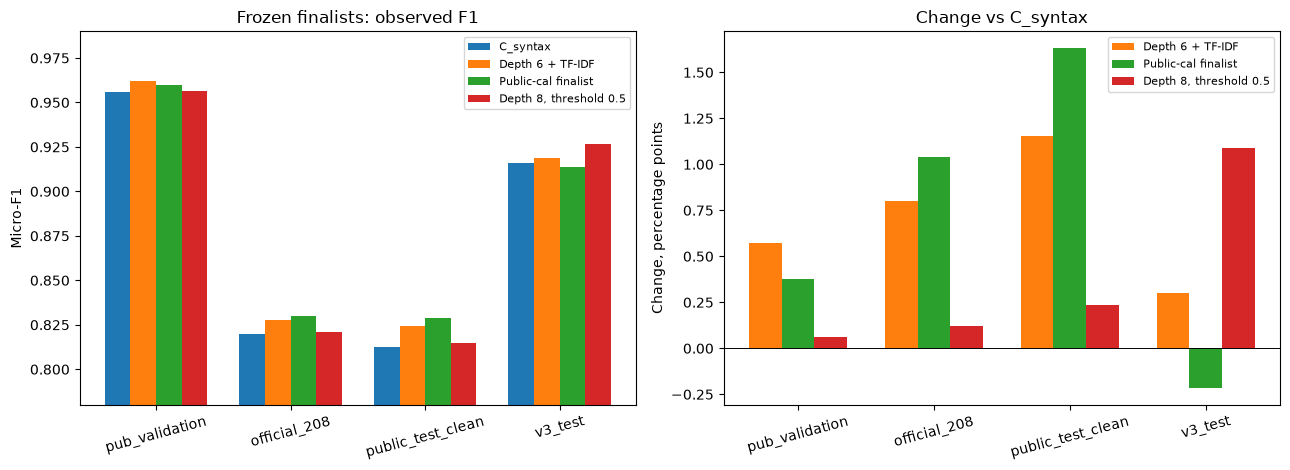

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
x=np.arange(len(datasets)); width=.19; colors=plt.rcParams['axes.prop_cycle'].by_key()['color']
for i, name in enumerate(names.values()):
 ax[0].bar(x+(i-1.5)*width, f1[i], width, label=name, color=colors[i])
ax[0].set_xticks(x, datasets, rotation=15); ax[0].set_ylim(.78, .99)
ax[0].set_ylabel('Micro-F1'); ax[0].set_title('Frozen finalists: observed F1')
ax[0].legend(fontsize=8)
delta = 100 * (f1[1:] - f1[0])
for i, name in enumerate(list(names.values())[1:]):
 ax[1].bar(x+(i-1)*.24, delta[i], .24, label=name, color=colors[i+1])
ax[1].set_xticks(x, datasets, rotation=15); ax[1].axhline(0, color='black', linewidth=.7)
ax[1].set_ylabel('Change, percentage points'); ax[1].set_title('Change vs C_syntax')
ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(P/'comparison.png', dpi=180, bbox_inches='tight')
plt.show()

In [3]:
rows=[]
for n in names:
 for d in datasets:
  m=metrics[n]['metrics'][d]; b=metrics['C_syntax_baseline__fixed']['metrics'][d]
  rows.append([names[n], d, round(m['micro_precision'],6), round(m['micro_recall'],6), m['fp'], m['fp']-b['fp'], m['fn'], m['fn']-b['fn'], round(m['exact_match'],6)])
table(['Model','Dataset','P','R','FP','delta FP','FN','delta FN','Exact'],rows)

Model,Dataset,P,R,FP,delta FP,FN,delta FN,Exact
C_syntax,pub_validation,0.943176,0.969432,107,0,56,0,0.838134
C_syntax,official_208,0.717557,0.955932,111,0,13,0,0.677885
C_syntax,public_test_clean,0.723077,0.927632,54,0,11,0,0.75
C_syntax,v3_test,0.912263,0.919598,88,0,80,0,0.756667
Depth 6 + TF-IDF,pub_validation,0.946617,0.97762,101,-6,41,-15,0.869684
Depth 6 + TF-IDF,official_208,0.722222,0.969492,110,-1,9,-4,0.701923
Depth 6 + TF-IDF,public_test_clean,0.733333,0.940789,52,-2,9,-2,0.776316
Depth 6 + TF-IDF,v3_test,0.926456,0.911558,72,-16,88,8,0.76
Public-cal finalist,pub_validation,0.940776,0.979803,113,6,37,-19,0.866941
Public-cal finalist,official_208,0.725888,0.969492,108,-3,9,-4,0.701923


По F1 основной кандидат улучшил три набора, однако V3 FN выросли 80→88. Групповой 95% CI изменения public test F1: [−0.576; +2.638] п.п.; он включает ноль. Глубина 8 сохранила порог 0.5 и снизила V3 FN до 64. Её выигрыш на public test мал и семантически смешанный. Максимум public test 0.830189 у отдельного финалиста сопровождается снижением V3 до 0.913767. Это не доказательство универсального улучшения.